# Lab 04-07 · Faraday's Law, Lenz's Law and Inductance

Companion to chapter [04-07](../../chapters/04-07-faraday-lenz-and-inductance.md). Handout: [README.md](README.md). The ngspice netlist [coupled_coils.cir](coupled_coils.cir) simulates Example 04-07.7; run it with `python tools/run_spice.py 04-07` from the repository root.

Cells marked **🔮 Predict** ask for a prediction *before* running. Nothing here is random.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, dblquad
from scipy.special import jv, ellipk, ellipe
from scipy.optimize import brentq
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
mu0, rho_cu = 1.25663706127e-6, 1.68e-8

## Part 1 — Faraday's law numerically

A small magnet (dipole moment 1 A·m²) moves along the axis of a 1 cm-radius loop. The flux through the loop is $\Phi(z) = \mu_0mR^2/[2(R^2 + z^2)^{3/2}]$; differentiate numerically to get the EMF.

**🔮 Predict:** if the magnet moves twice as fast, what happens to the peak EMF, and to the area under the EMF pulse?

v = 1.0 m/s: peak |EMF| = 5.395 mV; integral of EMF over the approach = -62.770 uWb
v = 2.0 m/s: peak |EMF| = 10.790 mV; integral of EMF over the approach = -62.770 uWb


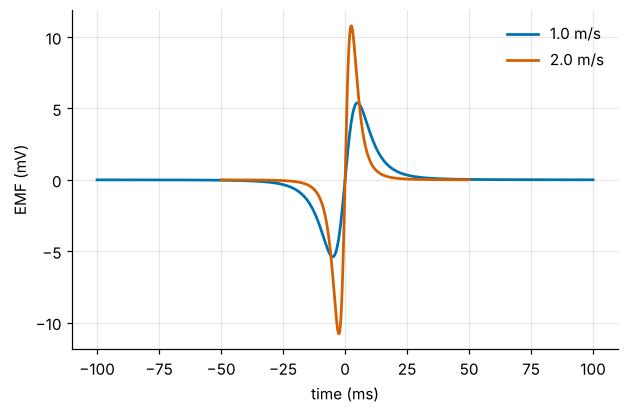

In [2]:
m, R = 1.0, 0.01
Phi = lambda z: mu0 * m * R**2 / (2 * (R**2 + z**2) ** 1.5)
for v in (1.0, 2.0):
    t = np.linspace(-0.1 / v, 0.1 / v, 40001)
    emf = -np.gradient(Phi(v * t), t)
    half = emf[t < 0]
    print(f"v = {v} m/s: peak |EMF| = {abs(emf).max()*1e3:.3f} mV; integral of EMF over the approach = {np.trapezoid(half, t[t < 0])*1e6:.3f} uWb")
    plt.plot(t * 1e3, emf * 1e3, label=f"{v} m/s")
plt.xlabel("time (ms)"); plt.ylabel("EMF (mV)"); plt.legend(); plt.show()

The peak doubles with speed, but the area under the pulse on the approach, $-\Delta\Phi$, is fixed by the flux change alone (62.77 µWb here: the flux at the loop minus the small flux at the starting point). Fast changes give big voltages; the total "volt-seconds" is set by the flux.

## Part 2 — The skin effect in a round wire

The exact AC resistance of a round wire of radius $a$ uses Bessel functions: $Z = \frac{k\rho}{2\pi a}\frac{J_0(ka)}{J_1(ka)}$ per unit length, with $k = (1 - j)/\delta$.

**🔮 Predict:** at what frequency does a 1 mm copper wire's resistance double?

1 mm wire: R_ac/R_dc = 1.466 at 100 kHz, 4.094 at 1 MHz; doubles at 202.7 kHz


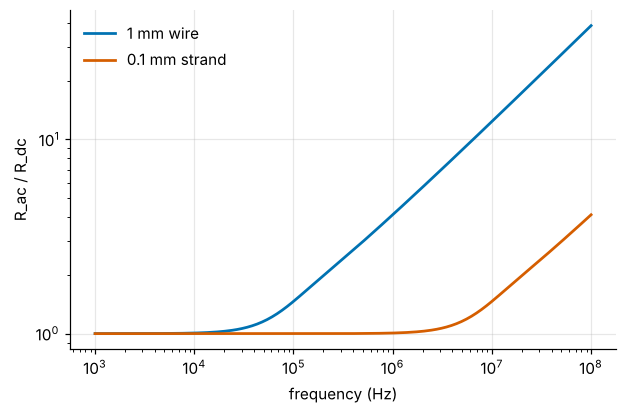

In [3]:
def ac_ratio(a, f):
    d = math.sqrt(rho_cu / (math.pi * f * mu0)); k = (1 - 1j) / d
    Z = k * rho_cu / (2 * math.pi * a) * jv(0, k * a) / jv(1, k * a)
    return Z.real / (rho_cu / (math.pi * a * a))
f = np.logspace(3, 8, 200)
for a, name in ((0.5e-3, "1 mm wire"), (0.05e-3, "0.1 mm strand")):
    plt.loglog(f, [ac_ratio(a, ff) for ff in f], label=name)
f2 = brentq(lambda ff: ac_ratio(0.5e-3, ff) - 2, 1e4, 1e7)
print(f"1 mm wire: R_ac/R_dc = {ac_ratio(0.5e-3, 1e5):.3f} at 100 kHz, {ac_ratio(0.5e-3, 1e6):.3f} at 1 MHz; doubles at {f2/1e3:.1f} kHz")
plt.xlabel("frequency (Hz)"); plt.ylabel("R_ac / R_dc"); plt.legend(); plt.show()

## Part 3 — A real solenoid's inductance

The long-solenoid formula ignores the ends, where field lines spread out. Compute the inductance of a uniformly wound coil (a current sheet) by adding the mutual inductance of every pair of thin rings, using Maxwell's formula for two coaxial loops.

**🔮 Predict:** is a 10 cm × 1 cm-radius, 500-turn coil's true inductance above or below 0.987 mH?

In [4]:
def M_loops(r1, r2, d):
    mm = 4 * r1 * r2 / ((r1 + r2) ** 2 + d * d); k = math.sqrt(mm)
    return mu0 * math.sqrt(r1 * r2) * ((2 / k - k) * ellipk(mm) - 2 / k * ellipe(mm))
r, l, N = 0.01, 0.1, 500
L_sheet = (N / l) ** 2 * 2 * quad(lambda s: (l - s) * M_loops(r, r, s), 0, l, limit=400, points=[1e-6, 1e-4])[0]
L_long = mu0 * N**2 * math.pi * r**2 / l
print(f"long-solenoid formula: {L_long*1e3:.4f} mH; current-sheet calculation: {L_sheet*1e3:.4f} mH; ratio (Nagaoka's K) = {L_sheet/L_long:.4f}")

long-solenoid formula: 0.9870 mH; current-sheet calculation: 0.9074 mH; ratio (Nagaoka's K) = 0.9194


The ends cost about 8%: a coil five times longer than its diameter is not "long". Nagaoka tabulated this correction in 1909; field solvers do it for arbitrary shapes.

## Part 4 — Mutual inductance of two loops

Compute $M$ between two coaxial 5 cm-radius loops by Neumann's formula, $M = \frac{\mu_0}{4\pi}\oint\oint\frac{d\vec l_1\cdot d\vec l_2}{|\vec r_1 - \vec r_2|}$, as a double integral, and compare with Maxwell's closed form.

**🔮 Predict:** how does $M$ fall with separation once the loops are far apart?

d = 5 cm: Neumann 24.704 nH, Maxwell 24.704 nH


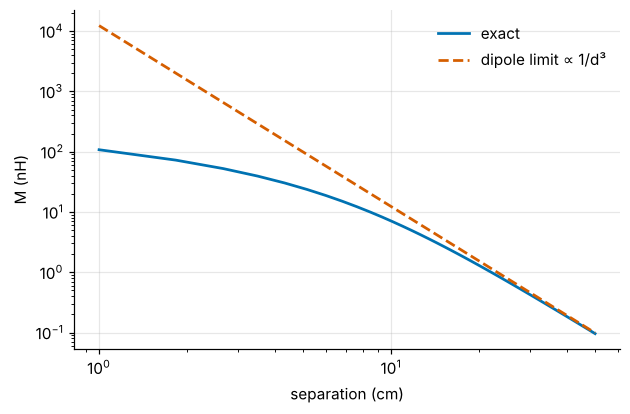

In [5]:
def M_neumann(R, d):
    f = lambda p1, p2: math.cos(p1 - p2) / math.sqrt(2 * R * R - 2 * R * R * math.cos(p1 - p2) + d * d)
    return mu0 / (4 * math.pi) * R * R * dblquad(f, 0, 2 * math.pi, 0, 2 * math.pi)[0]
R = 0.05
print(f"d = 5 cm: Neumann {M_neumann(R, 0.05)*1e9:.3f} nH, Maxwell {M_loops(R, R, 0.05)*1e9:.3f} nH")
d = np.linspace(0.01, 0.5, 60)
Md = [M_loops(R, R, dd) for dd in d]
plt.loglog(d * 100, np.array(Md) * 1e9, label="exact"); plt.loglog(d * 100, mu0 * math.pi * R**4 / (2 * d**3) * 1e9, "--", label="dipole limit ∝ 1/d³")
plt.xlabel("separation (cm)"); plt.ylabel("M (nH)"); plt.legend(); plt.show()

Far apart, $M$ falls as $1/d^3$ (each loop is a dipole to the other): coupling, and with it wireless power transfer, collapses quickly with distance. This is why chargers need the coils within millimeters.

## Part 5 — Gapped cores

For the core of Example 04-07.5, find the gap that gives 100 µH.

**🔮 Predict:** more or less than the 0.5 mm of the example?

In [6]:
N, A, lc, mur = 20, 4e-5, 0.05, 2000
L_of_g = lambda g: N**2 / (lc / (mur * mu0 * A) + g / (mu0 * A))
g100 = brentq(lambda g: L_of_g(g) - 100e-6, 0, 2e-3)
print(f"gap for 100 uH: {g100*1e3:.4f} mm; saturation current at 100 C there: {0.39*A*(lc/(mur*mu0*A) + g100/(mu0*A))/N:.3f} A")

gap for 100 uH: 0.1761 mm; saturation current at 100 C there: 3.120 A


A smaller gap (0.18 mm) gives more inductance but saturates at about 3.1 A: the same core stores a fixed energy budget for a given gap, and you choose where on the inductance–current trade to sit.

## Your turn

1. In Part 1, replace the dipole with a magnet that has a finite length (two opposite "charges" of magnetic flux). How does the EMF pulse change shape?
2. In Part 4, offset the second loop sideways by 5 cm. Can $M$ become zero or negative? What does that mean physically?